# 04 - BFCL: bài kiểm tra gọi hàm của Berkeley

**Đo cái gì?** Dữ liệu thật của Berkeley Function-Calling Leaderboard (v4): 4 nhóm - gọi 1 hàm, chọn trong nhiều hàm, gọi nhiều lần cùng lúc, và 'không hàm nào phù hợp' (phải không gọi gì).

**Vì sao cần?** Là đối chứng quốc tế cho notebook 03: nếu cả hai cùng xếp hạng các model giống nhau thì kết luận đáng tin hơn.

**Cách đọc biểu đồ:** Điểm = % câu làm đúng hoàn toàn. Nhóm 'irrelevance' đo việc model có biết im lặng khi không có hàm phù hợp.

**Giới hạn (để chuẩn bị phản biện):** Dùng cách chấm đơn giản hóa của nhóm (không phải bộ chấm AST chính thức) và 60 câu mỗi nhóm, nên không so trực tiếp với bảng xếp hạng BFCL; chỉ dùng để so các model của nhóm với nhau.

In [1]:
import slm_tools as st
import numpy as np
import pandas as pd
import bfcl_lite as B

C:\Users\HminhLab\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\cuda\__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
CATEGORIES = ["simple", "multiple", "parallel", "irrelevance"]
items = {c: B.load_items(c, n=60) for c in CATEGORIES}      # tải dữ liệu lần đầu từ GitHub

def measure(srv):
    result = {}
    for cat in CATEGORIES:
        answers = [srv.ask(B.messages(it), B.GRAMMAR, max_tokens=300)["text"] for it in items[cat]]
        result[cat] = float(np.mean([B.score(it, cat, a) for it, a in zip(items[cat], answers)]))
    result["overall"] = float(np.mean([result[c] for c in CATEGORIES]))
    return result

Chạy ô này sẽ lần lượt bật từng model, đo, rồi lưu vào thư mục `results/`. Nếu bị ngắt giữa chừng, chạy lại: model nào đã xong sẽ được bỏ qua.

In [3]:
st.run_all("bfcl", measure)

[đã có] SmolLM2-135M-Instruct (F16)
[đã có] Qwen2.5-0.5B-Instruct (F16)
[đã có] Qwen3-0.6B (F16)
[đã có] Gemma-3-1B-it (F16)
[đã có] Arch-Agent-1.5B (F16)
[đã có] xLAM-2-1B-fc-r (F16)
[đã có] Qwen3-1.7B (F16)
[đã có] Arch-Agent-3B (F16)
[đã có] Arch-Agent-1.5B (Q8)
[đã có] xLAM-2-1B-fc-r (Q8)
[đã có] Qwen3-1.7B (Q8)
[đã có] Arch-Agent-3B (Q8)
[đã có] Phi-4-mini-instruct (Q8)
[đã có] Arch-Agent-3B (Q4)
[đang chạy] Phi-4-mini-instruct (Q4)


   xong sau 108s
[đã có] Qwen2.5-0.5B-Instruct (Q8)
[đã có] Qwen2.5-0.5B-Instruct (Q4)
[đã có] Qwen3-0.6B (Q8)
[đã có] Qwen3-0.6B (Q4)
[đã có] Gemma-3-1B-it (Q4)
[đã có] Arch-Agent-1.5B (Q4)
[đã có] xLAM-2-1B-fc-r (Q4)
[đã có] Qwen3-1.7B (Q4)


## Biểu đồ 1 - Điểm tổng

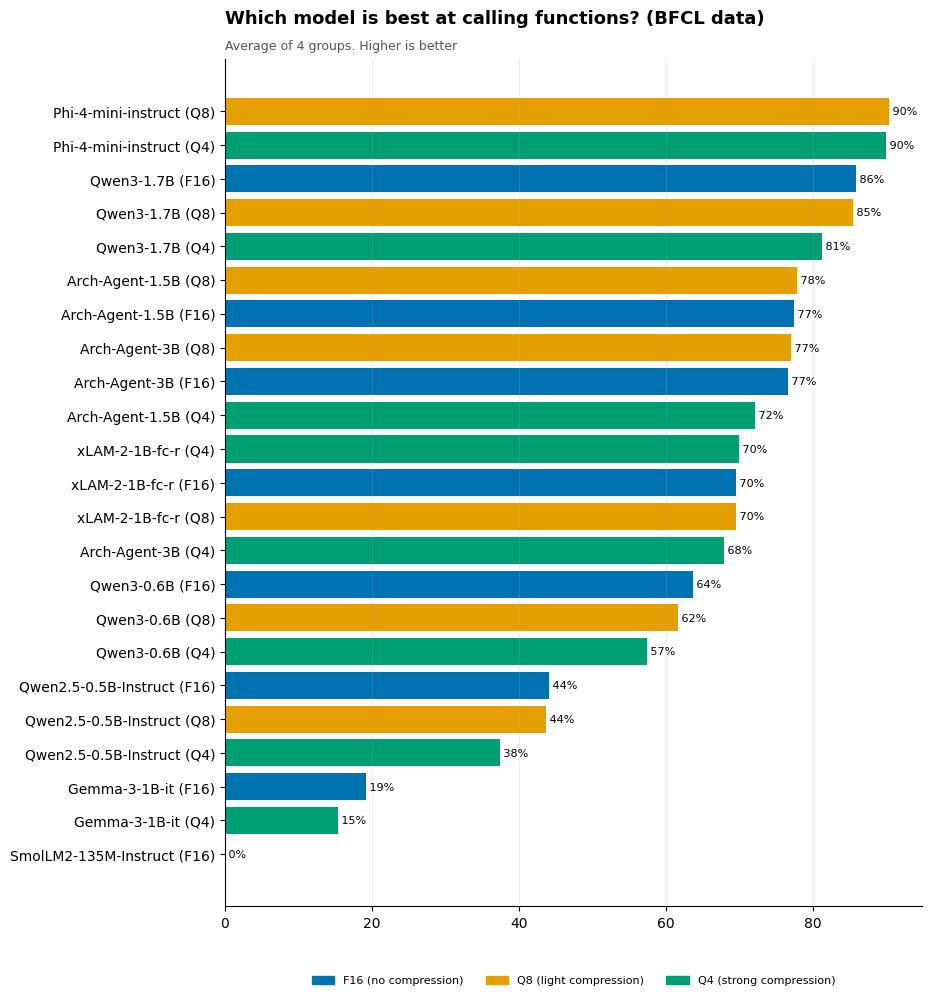

In [4]:
df = st.load("bfcl")
st.bar_chart(df, "overall", "Which model is best at calling functions? (BFCL data)", "Average of 4 groups. Higher is better", name="04_bfcl_overall")

## Biểu đồ 2 - Chi tiết từng nhóm

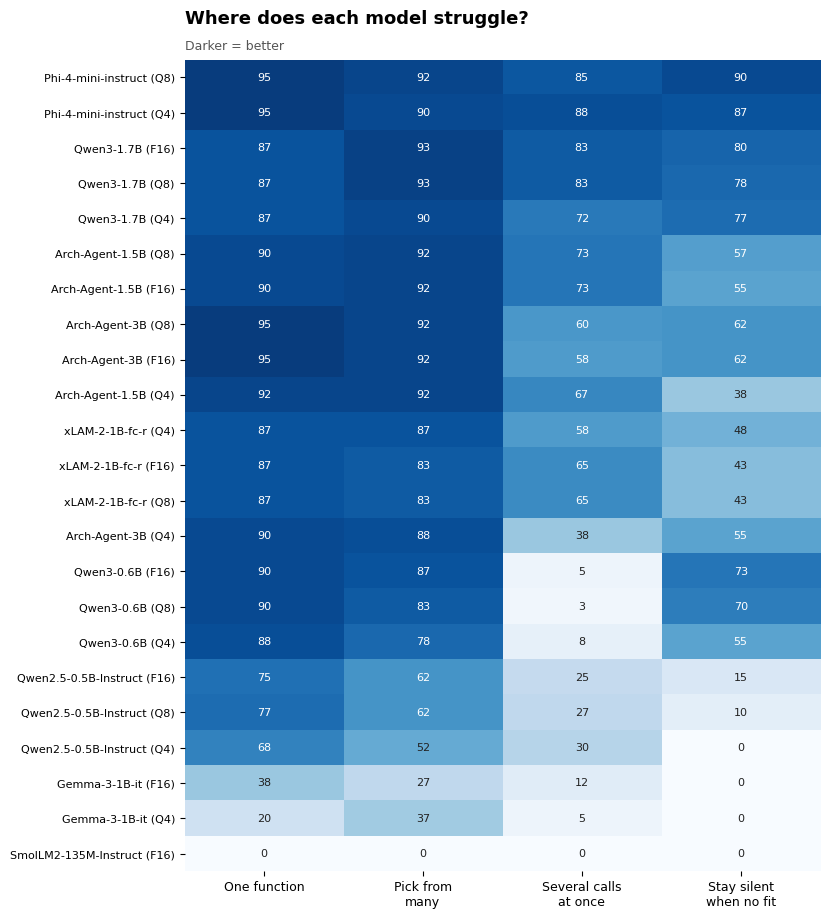

In [5]:
st.heatmap(df, {"simple": "One function", "multiple": "Pick from\nmany", "parallel": "Several calls\nat once",
                "irrelevance": "Stay silent\nwhen no fit"}, "Where does each model struggle?", name="04_bfcl_groups")